# Etapa 3 — Probabilidade: FRP elevada e períodos longos sem chuva

Pergunta: **entre os focos já detectados, como a proporção de FRP elevada varia com
períodos longos sem chuva?** A unidade é uma detecção em um pixel e horário (sensor
AQUA_M-T, bioma Amazônia, INPE), não um incêndio independente nem uma previsão de
surgimento de fogo. FRP é potência radiativa em MW; o rótulo elevado é estatístico,
sem equivalência com gravidade ambiental.

Conforme a seção 6 da especificação, esta etapa constrói a distribuição conjunta de duas
variáveis binárias, calcula marginais e condicionais, aplica a regra da cadeia a três
variáveis e o Teorema de Bayes, e verifica independência condicional dada a classe.
Não há modelo preditivo aqui: o foco é cálculo e interpretação.

**Variáveis binárias** (todos os cortes são aprendidos no treino da divisão):

| Símbolo | Evento (valor 1) | Corte |
|---|---|---|
| $F$ | FRP ≥ Q75 do treino (a classe das etapas 1 e 2) | Q75 de `frp` no treino |
| $S$ | período longo sem chuva: `numero_dias_sem_chuva` ≥ corte | mediana no treino |
| $R$ | chuva no instante da detecção: `precipitacao` > corte | mediana no treino (igual a 0 mm) |
| $H$, $M$ | `hora_utc` ≥ corte; `mes` ≥ corte (só na triagem de independência) | mediana no treino |

A mediana de `numero_dias_sem_chuva` é o mesmo corte da representação `discretizada` de
`utils.py`, o que mantém a Etapa 3 coerente com as etapas 1, 4 e 5. Para precipitação
a mediana é 0 mm e `discretizada` a tornaria constante; por isso $R$ usa a desigualdade
estrita (`> 0`). Os valores ausentes são imputados pela mediana do treino, como em
`preparar_particao`; a seção de sensibilidade mostra o efeito dessa escolha. Usamos os
folds espaciais de 2024; 2025 permanece reservado ao teste final.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from probabilidade import (binarizar, contagens_conjuntas, conjunta, marginal, condicional,
                           reconstruir_pela_cadeia, bayes, bayes_binario, qui_quadrado_2x2,
                           phi, informacao_mutua, independencia_condicional,
                           diferenca_risco_por_grupo)
from utils import ATRIBUTOS, carregar_dados, iterar_folds, preparar_particao

np.random.seed(42)
pd.set_option("display.max_rows", 100)
pd.set_option("display.precision", 6)

def fmt_p(p):
    return "< 1e-300" if p < 1e-300 else f"{p:.3e}"

## Verificações didáticas — dados sintéticos

Antes dos dados reais, conferimos as funções com casos de resposta conhecida: o exemplo
de Bayes da especificação ($P(D\mid S)=0{,}8\times0{,}05/0{,}15\approx0{,}267$), uma conjunta
construída como produto de marginais (independência exata) e uma dependente.

In [2]:
# Exemplo de Bayes da especificação (seção 6.3)
assert np.isclose(bayes(0.8, 0.05, 0.15), 0.8 * 0.05 / 0.15)
assert np.isclose(bayes(0.8, 0.05, 0.15), 0.26667, atol=1e-5)
# Probabilidade total: P(S) = 0,8*0,05 + P(S|~D)*0,95; com P(S|~D)=0,1157894... dá 0,15
assert np.isclose(bayes_binario(0.8, (0.15 - 0.04) / 0.95, 0.05), bayes(0.8, 0.05, 0.15))

# Conjunta de duas binárias: soma 1, marginais e condicionais
a = np.array([0, 0, 0, 1, 1, 1, 1, 1])
b = np.array([0, 0, 1, 0, 1, 1, 1, 1])
J = conjunta(a, b)
assert J.shape == (2, 2) and np.isclose(J.sum(), 1)
assert np.allclose(marginal(J, (0,)), [3 / 8, 5 / 8])
assert np.allclose(marginal(J, (1,)), [3 / 8, 5 / 8])
assert np.isclose(condicional(J, (1,), (0,))[1, 1], 4 / 5)      # P(b=1 | a=1)
assert np.allclose(condicional(J, (1,), (0,)).sum(axis=0), 1)   # cada coluna soma 1
assert np.isnan(condicional(conjunta([0, 0], [0, 1]), (0,), (1,))[:, 1]).sum() == 0

# Regra da cadeia com 3 variáveis, em qualquer ordem
rng = np.random.default_rng(0)
x, y, z = (rng.integers(0, 2, 500) for _ in range(3))
J3 = conjunta(x, y, z)
for ordem in [(0, 1, 2), (2, 0, 1), (1, 2, 0)]:
    assert np.allclose(reconstruir_pela_cadeia(J3, ordem), J3)

# Independência: produto de marginais dá phi = 0; dependência exata dá |phi| = 1
produto = np.outer([0.3, 0.7], [0.4, 0.6])
assert np.isclose(informacao_mutua(produto), 0, atol=1e-12)
assert np.isclose(phi(np.array([[12, 18], [28, 42]])), 0)
assert np.isclose(phi(np.array([[50, 0], [0, 50]])), 1)
assert np.isclose(informacao_mutua(np.array([[0.5, 0], [0, 0.5]])), 1)

# Independência condicional: X e Y dependem só de C, logo são independentes dado C
c = rng.integers(0, 2, 20000)
xc = (rng.random(20000) < np.where(c == 1, 0.8, 0.2)).astype(int)
yc = (rng.random(20000) < np.where(c == 1, 0.7, 0.3)).astype(int)
assert abs(phi(contagens_conjuntas(xc, yc))) > 0.2              # marginalmente dependentes
linhas, teste = independencia_condicional(xc, yc, c)
assert all(abs(l["phi"]) < 0.05 for l in linhas)                # condicionalmente independentes

for chamada in [lambda: conjunta([0, 2], [0, 1]), lambda: conjunta([0, 1], [0]),
                lambda: conjunta([]), lambda: binarizar([1.0, np.nan], 0),
                lambda: bayes(0.5, 0.5, 0), lambda: marginal(J, (0, 0))]:
    try:
        chamada()
    except ValueError:
        continue
    raise AssertionError("Entrada inválida deveria falhar.")
print("Verificações sintéticas concluídas.")

Verificações sintéticas concluídas.


## Desenvolvimento de 2024

A leitura confere o hash do produto entregue. As ausências permanecem nesta tabela; as
transformações são aprendidas somente no treino de cada divisão.

In [3]:
dados = carregar_dados(2024)
assert len(dados) == 140346 and dados["ano"].eq(2024).all()

def variaveis_binarias(X, y_cls, medianas):
    # Todas as variáveis usam apenas os cortes do treino (medianas já aprendidas).
    return {"F": y_cls.to_numpy().astype(int),
            "S": binarizar(X["numero_dias_sem_chuva"], medianas["numero_dias_sem_chuva"]),
            "R": binarizar(X["precipitacao"], medianas["precipitacao"], estrito=True),
            "H": binarizar(X["hora_utc"], medianas["hora_utc"]),
            "M": binarizar(X["mes"], medianas["mes"])}

def dividir(fold_alvo=0, estrategia="espacial"):
    for fold, treino, validacao in iterar_folds(dados, estrategia):
        if fold == fold_alvo:
            p = preparar_particao(treino, validacao, "numerica")
            tr = variaveis_binarias(p.X_treino, p.y_cls_treino, p.parametros["medianas"])
            va = variaveis_binarias(p.X_avaliacao, p.y_cls_avaliacao, p.parametros["medianas"])
            return fold, treino, validacao, p, tr, va

fold, treino, validacao, p, V, Vval = dividir(0)
assert not set(treino.grupo_validacao) & set(validacao.grupo_validacao)
med = p.parametros["medianas"]
n = len(treino)
print(f"Fold espacial {fold}: treino={n:,}; validação={len(validacao):,}; Q75 do treino = {p.limiar_frp:.2f} MW")

Fold espacial 0: treino=112,277; validação=28,069; Q75 do treino = 59.50 MW


## Definição das variáveis e cortes (treino do fold 0)

Os cortes vêm das medianas do treino; a validação só os recebe. Como $F$ é definida
pelo Q75 de FRP no treino, esperamos $P(F=1)\approx 0{,}25$ no treino. Empates podem
elevar um pouco essa proporção, e a validação pode diferir.

In [4]:
definicao = {"F": ("FRP ≥ Q75 do treino", p.limiar_frp),
             "S": ("dias sem chuva ≥ corte", med["numero_dias_sem_chuva"]),
             "R": ("precipitação > corte", med["precipitacao"]),
             "H": ("hora_utc ≥ corte", med["hora_utc"]),
             "M": ("mês ≥ corte", med["mes"])}
tabela_cortes = pd.DataFrame({"evento (valor 1)": {k: v[0] for k, v in definicao.items()},
                              "corte (treino)": {k: v[1] for k, v in definicao.items()},
                              "P(=1) treino": {k: V[k].mean() for k in definicao},
                              "P(=1) validação": {k: Vval[k].mean() for k in definicao}})
display(tabela_cortes)
assert all(np.isin(V[k], (0, 1)).all() and len(V[k]) == n for k in V)
assert med["precipitacao"] == 0 and V["R"].mean() < 0.5

,evento (valor 1),corte (treino),P(=1) treino,P(=1) validação
F,FRP ≥ Q75 do treino,59.5,0.250318,0.226406
S,dias sem chuva ≥ corte,10.0,0.523705,0.539848
R,precipitação > corte,0.0,0.187269,0.185365
H,hora_utc ≥ corte,18.1,0.518174,0.228081
M,mês ≥ corte,9.0,0.526475,0.642916


## 1. Distribuição conjunta de $F$ e $S$ (4 eventos atômicos)

Cada detecção cai em exatamente um dos quatro eventos atômicos
$(F,S)\in\{0,1\}^2$. A distribuição conjunta empírica é a contagem de cada evento dividida
por $N$; ela precisa somar 1.

In [5]:
cont_FS = contagens_conjuntas(V["F"], V["S"])
J_FS = conjunta(V["F"], V["S"])          # eixo 0 = F, eixo 1 = S
assert np.isclose(J_FS.sum(), 1) and cont_FS.sum() == n

rotulos_F = ["F=0 (FRP < Q75)", "F=1 (FRP ≥ Q75)"]
rotulos_S = ["S=0 (poucos dias)", "S=1 (período longo)"]
display(Markdown("**Contagens**"))
display(pd.DataFrame(cont_FS, index=rotulos_F, columns=rotulos_S)
        .assign(total=lambda t: t.sum(axis=1)).pipe(lambda t: pd.concat([t, t.sum().rename("total").to_frame().T])))
display(Markdown("**Probabilidades conjuntas $P(F,S)$** (soma = 1)"))
display(pd.DataFrame(J_FS, index=rotulos_F, columns=rotulos_S)
        .assign(**{"P(F)": lambda t: t.sum(axis=1)}).pipe(lambda t: pd.concat([t, t.sum().rename("P(S)").to_frame().T])))

**Contagens**

,S=0 (poucos dias),S=1 (período longo),total
F=0 (FRP < Q75),43487,40685,84172
F=1 (FRP ≥ Q75),9990,18115,28105
total,53477,58800,112277


**Probabilidades conjuntas $P(F,S)$** (soma = 1)

,S=0 (poucos dias),S=1 (período longo),P(F)
F=0 (FRP < Q75),0.387319,0.362363,0.749682
F=1 (FRP ≥ Q75),0.088976,0.161342,0.250318
P(S),0.476295,0.523705,1.000000


## 2. Marginais e condicionais

As marginais somam a conjunta sobre a outra variável. As condicionais dividem a conjunta
pela marginal do condicionante: $P(F\mid S)=P(F,S)/P(S)$. A pergunta central compara
$P(F=1\mid S=1)$ com $P(F=1\mid S=0)$. Detecções do mesmo município não são independentes,
então o intervalo de 95% da diferença vem de bootstrap por **município** (2.000
reamostragens, semente 42), não de contagem de linhas.

In [6]:
P_F, P_S = marginal(J_FS, (0,)), marginal(J_FS, (1,))
P_F_dado_S = condicional(J_FS, (0,), (1,))      # eixos: F, S
P_S_dado_F = condicional(J_FS, (1,), (0,))      # eixos: S, F
assert np.allclose(P_F_dado_S.sum(axis=0), 1) and np.allclose(P_S_dado_F.sum(axis=0), 1)

f1_s1, f1_s0 = P_F_dado_S[1, 1], P_F_dado_S[1, 0]
dif, ic_inf, ic_sup = diferenca_risco_por_grupo(V["F"], V["S"], treino.grupo_validacao.to_numpy())
assert np.isclose(dif, f1_s1 - f1_s0)
resumo = pd.DataFrame({"valor": {
    "P(F=1)": P_F[1], "P(S=1)": P_S[1],
    "P(F=1 | S=1)": f1_s1, "P(F=1 | S=0)": f1_s0,
    "P(S=1 | F=1)": P_S_dado_F[1, 1], "P(S=1 | F=0)": P_S_dado_F[1, 0],
    "diferença P(F=1|S=1) − P(F=1|S=0)": dif,
    "IC 95% (bootstrap por município), inferior": ic_inf,
    "IC 95% (bootstrap por município), superior": ic_sup,
    "razão P(F=1|S=1) / P(F=1|S=0)": f1_s1 / f1_s0}})
display(resumo)

,valor
P(F=1),0.250318
P(S=1),0.523705
P(F=1 | S=1),0.308078
P(F=1 | S=0),0.186809
P(S=1 | F=1),0.644547
P(S=1 | F=0),0.483356
diferença P(F=1|S=1) − P(F=1|S=0),0.121269
"IC 95% (bootstrap por município), inferior",0.098210
"IC 95% (bootstrap por município), superior",0.142055
razão P(F=1|S=1) / P(F=1|S=0),1.649159


### Como a proporção de FRP elevada varia com os dias sem chuva

Para ver além do corte único, dividimos `numero_dias_sem_chuva` em faixas cujas bordas
são quantis do treino (25%, 50%, 75% e 90%). As mesmas bordas são aplicadas à validação
espacial, só para checar se o padrão se mantém em municípios não vistos.

,n treino,P(F=1 | faixa) treino,n validação,P(F=1 | faixa) validação
faixa (dias),,,,
< 3,22192,0.163077,5413,0.146314
3–9,31285,0.203644,7503,0.177396
10–29,29829,0.264105,8946,0.234071
30–80,17673,0.325921,3296,0.286408
≥ 81,11298,0.396265,2911,0.410168


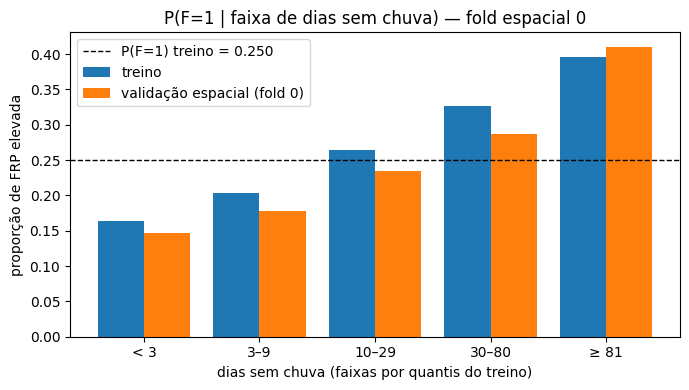

In [7]:
bordas = np.unique(p.X_treino["numero_dias_sem_chuva"].quantile([.25, .5, .75, .9]).to_numpy())
rot = [f"< {bordas[0]:g}"] + [f"{bordas[i]:g}–{bordas[i + 1] - 1:g}" for i in range(len(bordas) - 1)] + [f"≥ {bordas[-1]:g}"]
faixa_tr = np.digitize(p.X_treino["numero_dias_sem_chuva"], bordas)
faixa_va = np.digitize(p.X_avaliacao["numero_dias_sem_chuva"], bordas)
por_faixa = pd.DataFrame({
    "faixa (dias)": rot,
    "n treino": np.bincount(faixa_tr, minlength=len(rot)),
    "P(F=1 | faixa) treino": [V["F"][faixa_tr == k].mean() for k in range(len(rot))],
    "n validação": np.bincount(faixa_va, minlength=len(rot)),
    "P(F=1 | faixa) validação": [Vval["F"][faixa_va == k].mean() for k in range(len(rot))]}).set_index("faixa (dias)")
display(por_faixa)
assert (por_faixa["n treino"] > 0).all() and (por_faixa["n validação"] > 0).all()
monotona_treino = bool(np.all(np.diff(por_faixa["P(F=1 | faixa) treino"]) > 0))
monotona_valid = bool(np.all(np.diff(por_faixa["P(F=1 | faixa) validação"]) > 0))

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(rot))
ax.bar(x - 0.2, por_faixa["P(F=1 | faixa) treino"], 0.4, label="treino")
ax.bar(x + 0.2, por_faixa["P(F=1 | faixa) validação"], 0.4, label="validação espacial (fold 0)")
ax.axhline(P_F[1], color="k", ls="--", lw=1, label=f"P(F=1) treino = {P_F[1]:.3f}")
ax.set_xticks(x, rot)
ax.set_xlabel("dias sem chuva (faixas por quantis do treino)")
ax.set_ylabel("proporção de FRP elevada")
ax.set_title("P(F=1 | faixa de dias sem chuva) — fold espacial 0")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Regra da cadeia com três variáveis

Tomamos $R$ (chuva no instante), $S$ (período longo sem chuva) e $F$ (FRP elevada).
A regra da cadeia fatora a conjunta de três variáveis em

$$P(R,S,F)=P(R)\,P(S\mid R)\,P(F\mid S,R).$$

Esta ordem, da condição atmosférica para a intensidade do foco, é a que usaremos como
ponto de partida para o DAG da Etapa 5. Como as probabilidades são frequências
empíricas, o produto deve reproduzir cada um dos oito eventos atômicos, em qualquer
ordem das variáveis.

In [8]:
J3 = conjunta(V["R"], V["S"], V["F"])          # eixos: 0=R, 1=S, 2=F
pR = marginal(J3, (0,))                         # P(R)
pS_R = condicional(J3, (1,), (0,))              # P(S | R), indexado [s, r]
pF_SR = condicional(J3, (2,), (0, 1))           # P(F | R, S), indexado [f, r, s]

linhas = []
for r in (0, 1):
    for s in (0, 1):
        for f in (0, 1):
            fatores = (pR[r], pS_R[s, r], pF_SR[f, r, s])
            linhas.append({"R": r, "S": s, "F": f, "P(R)": fatores[0], "P(S|R)": fatores[1],
                           "P(F|S,R)": fatores[2], "produto": np.prod(fatores), "P(R,S,F) empírica": J3[r, s, f]})
cadeia = pd.DataFrame(linhas)
display(cadeia)
assert np.isclose(cadeia["P(R,S,F) empírica"].sum(), 1)
assert np.allclose(cadeia["produto"], cadeia["P(R,S,F) empírica"], atol=1e-12)
for ordem in [(0, 1, 2), (2, 1, 0), (1, 0, 2), (2, 0, 1)]:
    assert np.allclose(reconstruir_pela_cadeia(J3, ordem), J3, atol=1e-12)
print("A fatoração reproduz a conjunta nos 8 eventos e nas ordens testadas.")

,R,S,F,P(R),P(S|R),"P(F|S,R)",produto,"P(R,S,F) empírica"
0,0,0,0,0.812731,0.399776,0.800576,0.260116,0.260116
1,0,0,1,0.812731,0.399776,0.199424,0.064795,0.064795
2,0,1,0,0.812731,0.600224,0.684066,0.333701,0.333701
3,0,1,1,0.812731,0.600224,0.315934,0.154119,0.154119
4,1,0,0,0.187269,0.808380,0.840266,0.127203,0.127203
5,1,0,1,0.187269,0.808380,0.159734,0.024181,0.024181
6,1,1,0,0.187269,0.191620,0.798709,0.028661,0.028661
7,1,1,1,0.187269,0.191620,0.201291,0.007223,0.007223


A fatoração reproduz a conjunta nos 8 eventos e nas ordens testadas.


## 4. Teorema de Bayes

Na especificação, a conta é $P(D\mid S)=P(S\mid D)P(D)/P(S)$. Aqui, o condicionante
informativo é o período longo sem chuva ($S$) e a hipótese é FRP elevada ($F$):

$$P(F=1\mid S=1)=\frac{P(S=1\mid F=1)\,P(F=1)}{P(S=1)},
\qquad P(S=1)=\sum_{f}P(S=1\mid F=f)P(F=f).$$

**Causal versus diagnóstico.** A hipótese física é que mais dias sem chuva ressecam o
combustível e favorecem focos mais intensos: o sentido causal plausível é $S\to F$. Logo
$P(F\mid S)$ está na direção causal e $P(S\mid F)$ é diagnóstica (dado um foco intenso,
quão provável é ter havido seca longa). Os dados são observacionais; nenhuma das duas
quantidades prova causalidade, porque mês, região e vegetação podem confundir a relação.
Bayes converte a informação diagnóstica na causal e vice-versa, e é a base do Naive Bayes
da Etapa 4, que modela $P(\text{atributos}\mid\text{classe})$ e inverte.

In [9]:
p_S1_F1, p_S1_F0, p_F1 = P_S_dado_F[1, 1], P_S_dado_F[1, 0], P_F[1]
p_S1 = p_S1_F1 * p_F1 + p_S1_F0 * (1 - p_F1)          # probabilidade total
assert np.isclose(p_S1, P_S[1])
via_bayes = bayes(p_S1_F1, p_F1, p_S1)
assert np.isclose(via_bayes, bayes_binario(p_S1_F1, p_S1_F0, p_F1))
assert np.isclose(via_bayes, f1_s1) and np.isclose(via_bayes, J_FS[1, 1] / J_FS[:, 1].sum())

# Bayes na direção inversa: P(S=1 | F=1) a partir de P(F=1 | S=1)
inversa = bayes(f1_s1, P_S[1], p_F1)
assert np.isclose(inversa, p_S1_F1)

display(pd.DataFrame({"valor": {
    "P(S=1 | F=1)  (diagnóstica)": p_S1_F1, "P(S=1 | F=0)": p_S1_F0, "P(F=1)  (a priori)": p_F1,
    "P(S=1) por probabilidade total": p_S1,
    "P(F=1 | S=1) por Bayes": via_bayes, "P(F=1 | S=1) direta nas contagens": f1_s1,
    "P(F=1 | S=1) / P(F=1)  (fator de aumento)": via_bayes / p_F1}}))

,valor
P(S=1 | F=1) (diagnóstica),0.644547
P(S=1 | F=0),0.483356
P(F=1) (a priori),0.250318
P(S=1) por probabilidade total,0.523705
P(F=1 | S=1) por Bayes,0.308078
P(F=1 | S=1) direta nas contagens,0.308078
P(F=1 | S=1) / P(F=1) (fator de aumento),1.230745


**Por que a lógica de primeira ordem (LPO) não expressa isso.** Uma sentença como
$\forall x\,(\text{PeríodoLongo}(x)\Rightarrow\text{FRPElevada}(x))$ é falsa: há focos
com período longo sem chuva e FRP baixa. O fato verdadeiro é uma **proporção**
(a probabilidade acima), que a LPO, cujas sentenças são só verdadeiras ou falsas, não
representa nem combina com outras evidências. Probabilidade condicional mede o grau de
associação, e o Teorema de Bayes diz como atualizá-lo quando a evidência muda.

## 5. Independência e independência condicional dada a classe

Duas variáveis são independentes se $P(A,B)=P(A)P(B)$; $A$ e $B$ são condicionalmente
independentes dada $C$ se $P(A,B\mid C)=P(A\mid C)P(B\mid C)$ para cada valor de $C$.
Para a Etapa 4, a pergunta é se os atributos são independentes **dada a classe** $F$,
suposição do Naive Bayes. Testamos $S$ (período longo sem chuva) e $R$ (chuva no
instante), dois atributos meteorológicos do mesmo foco.

Medimos o afastamento por três quantidades: o coeficiente $\phi$ (correlação entre
binárias, 0 sob independência), a informação mútua em bits e o maior
$|P(A,B\mid c)-P(A\mid c)P(B\mid c)|$. O teste qui-quadrado dá um p-valor, mas com
mais de 100 mil linhas quase qualquer desvio é "significativo", e a dependência
espacial infla essa significância; por isso a magnitude é mais informativa.

In [10]:
# (a) independência marginal entre F e S, e entre S e R
for nome, (u, v) in {"F e S": (V["F"], V["S"]), "S e R": (V["S"], V["R"])}.items():
    c = contagens_conjuntas(u, v)
    q, pv = qui_quadrado_2x2(c)
    print(f"{nome}: phi = {phi(c):+.4f}; I = {informacao_mutua(c / c.sum()):.4f} bits; qui2 = {q:,.1f}; p = {fmt_p(pv)}")

# (b) independência condicional de S e R dada a classe F
linhas, teste_global = independencia_condicional(V["S"], V["R"], V["F"])
tab_ci = pd.DataFrame(linhas).assign(p_valor=lambda t: t["p_valor"].map(fmt_p)).set_index("classe")
display(tab_ci)
print(f"Teste global (soma dos qui-quadrados, {teste_global['graus_liberdade']} g.l.): "
      f"qui2 = {teste_global['qui2']:,.1f}; p = {fmt_p(teste_global['p_valor'])}")

# (c) o produto das condicionais não reproduz a condicional conjunta (classe F=1)
J_SRF = conjunta(V["S"], V["R"], V["F"])
conj_dado_F1 = condicional(J_SRF, (0, 1), (2,))[..., 1]                 # P(S, R | F=1), eixos S, R
prod_dado_F1 = np.outer(condicional(J_SRF, (0,), (2,))[:, 1], condicional(J_SRF, (1,), (2,))[:, 1])
display(Markdown("**Classe $F=1$:** $P(S,R\\mid F=1)$ contra $P(S\\mid F=1)\\,P(R\\mid F=1)$"))
display(pd.concat({"P(S,R | F=1)": pd.DataFrame(conj_dado_F1, index=["S=0", "S=1"], columns=["R=0", "R=1"]),
                   "P(S|F=1) P(R|F=1)": pd.DataFrame(prod_dado_F1, index=["S=0", "S=1"], columns=["R=0", "R=1"])}, axis=1))
assert np.isclose(conj_dado_F1.sum(), 1) and np.isclose(prod_dado_F1.sum(), 1)

F e S: phi = +0.1398; I = 0.0143 bits; qui2 = 2,194.7; p = < 1e-300
S e R: phi = -0.3192; I = 0.0774 bits; qui2 = 11,437.9; p = < 1e-300


,n,phi,informacao_mutua_bits,desvio_maximo,qui2,p_valor
classe,,,,,,
0,84172,-0.307023,0.07276,0.062262,7934.321414,< 1e-300
1,28105,-0.328026,0.07485,0.052008,3024.135167,< 1e-300


Teste global (soma dos qui-quadrados, 2 g.l.): qui2 = 10,958.5; p = < 1e-300


**Classe $F=1$:** $P(S,R\mid F=1)$ contra $P(S\mid F=1)\,P(R\mid F=1)$

P(S,R | F=1)           P(S|F=1) P(R|F=1)          
             R=0       R=1               R=0       R=1
S=0     0.258851  0.096602          0.310858  0.044594
S=1     0.615691  0.028856          0.563684  0.080864

### Triagem de pares de atributos dada a classe

Para orientar as etapas 4 e 5, repetimos o cálculo em todos os pares entre $S$, $R$, $H$
(hora) e $M$ (mês). A coluna `I(A;B|F)` é a informação mútua condicional, a média das
informações mútuas por classe ponderada por $P(F=c)$.

In [11]:
from itertools import combinations
triagem = []
for a_, b_ in combinations(["S", "R", "H", "M"], 2):
    linhas_par, teste_par = independencia_condicional(V[a_], V[b_], V["F"])
    peso = {l["classe"]: l["n"] / n for l in linhas_par}
    triagem.append({"par": f"{a_},{b_}",
                    "phi | F=0": linhas_par[0]["phi"], "phi | F=1": linhas_par[1]["phi"],
                    "I(A;B|F) bits": sum(peso[l["classe"]] * l["informacao_mutua_bits"] for l in linhas_par),
                    "p global": fmt_p(teste_par["p_valor"])})
triagem = pd.DataFrame(triagem).set_index("par").sort_values("I(A;B|F) bits", ascending=False)
display(triagem)

,phi | F=0,phi | F=1,I(A;B|F) bits,p global
par,,,,
"S,R",-0.307023,-0.328026,0.073283,< 1e-300
"S,M",-0.276936,-0.260765,0.054384,< 1e-300
"R,M",0.184965,0.239571,0.029981,< 1e-300
"H,M",-0.120889,-0.134714,0.011214,< 1e-300
"R,H",-0.047757,0.010488,0.001252,4.395e-43
"S,H",-0.009671,-0.037368,0.000303,5.872e-11


## Estabilidade nos cinco folds espaciais

Repetimos o cálculo em cada fold. Em cada rodada, o corte de $S$, o Q75 e as demais
medianas são reaprendidos no treino da rodada e aplicados à validação. As colunas
`treino` e `valid.` comparam a estimativa nos municípios usados no cálculo com a
estimativa em municípios não vistos. O desvio-padrão é **amostral (`ddof=1`)** entre os
cinco folds, com o mesmo peso em cada um; não é intervalo de confiança.

In [12]:
registros = []
for fold_k in range(5):
    _, tr_k, va_k, p_k, A, B = dividir(fold_k)
    g = lambda W, s: W["F"][W["S"] == s].mean()
    c_tr = [l["phi"] for l in independencia_condicional(A["S"], A["R"], A["F"])[0]]
    c_va = [l["phi"] for l in independencia_condicional(B["S"], B["R"], B["F"])[0]]
    registros.append({"fold": fold_k, "Q75 (MW)": p_k.limiar_frp,
                      "corte S (dias)": p_k.parametros["medianas"]["numero_dias_sem_chuva"],
                      "P(F=1|S=1) treino": g(A, 1), "P(F=1|S=0) treino": g(A, 0),
                      "P(F=1|S=1) valid.": g(B, 1), "P(F=1|S=0) valid.": g(B, 0),
                      "diferença treino": g(A, 1) - g(A, 0), "diferença valid.": g(B, 1) - g(B, 0),
                      "phi(S,R|F=0) treino": c_tr[0], "phi(S,R|F=1) treino": c_tr[1],
                      "phi(S,R|F=0) valid.": c_va[0], "phi(S,R|F=1) valid.": c_va[1]})
folds = pd.DataFrame(registros).set_index("fold")
display(folds)
display(folds.agg(["mean", "std"]).T)
assert (folds["diferença valid."] > 0).all() and (folds["diferença treino"] > 0).all()
assert (folds[[c for c in folds if c.startswith("phi")]] < -0.1).all().all()

,Q75 (MW),corte S (dias),P(F=1|S=1) treino,P(F=1|S=0) treino,P(F=1|S=1) valid.,P(F=1|S=0) valid.,diferença treino,diferença valid.,"phi(S,R|F=0) treino","phi(S,R|F=1) treino","phi(S,R|F=0) valid.","phi(S,R|F=1) valid."
fold,,,,,,,,,,,,
0,59.5,10.0,0.308078,0.186809,0.279285,0.164370,0.121269,0.114915,-0.307023,-0.328026,-0.324646,-0.334384
1,58.0,11.0,0.307691,0.190560,0.334263,0.184896,0.117131,0.149367,-0.305227,-0.317897,-0.294279,-0.343964
2,58.6,10.0,0.306874,0.188553,0.305507,0.173635,0.118321,0.131872,-0.308455,-0.322382,-0.318104,-0.362437
3,57.9,11.0,0.309722,0.188173,0.328759,0.195972,0.121549,0.132788,-0.301223,-0.318426,-0.311509,-0.342119
4,58.1,11.0,0.314835,0.182138,0.302004,0.214741,0.132697,0.087264,-0.309268,-0.344490,-0.278316,-0.246190


,mean,std
Q75 (MW),58.420000,0.661060
corte S (dias),10.600000,0.547723
P(F=1|S=1) treino,0.309440,0.003189
P(F=1|S=0) treino,0.187247,0.003156
P(F=1|S=1) valid.,0.309964,0.022182
P(F=1|S=0) valid.,0.186723,0.019652
diferença treino,0.122193,0.006169
diferença valid.,0.123241,0.023515
"phi(S,R|F=0) treino",-0.306239,0.003197
"phi(S,R|F=1) treino",-0.326244,0.010975


## Sensibilidade das escolhas de corte e de ausências

As escolhas que mais podem mexer nos números são (i) como tratar os 1,2–1,5% de dias sem
chuva ausentes, que a imputação pela mediana coloca em $S=1$, e (ii) o que significa
"período longo". Recalculamos a diferença no fold 0 com **casos completos** (sem
imputar) e com $S$ definido pelo **Q75** de dias sem chuva no treino, em vez da mediana.
Em todas as variantes o corte vem só do treino.

In [13]:
def estimar(S_tr, F_tr, grupos, S_va=None, F_va=None):
    f1, f0 = F_tr[S_tr == 1].mean(), F_tr[S_tr == 0].mean()
    d, lo, hi = diferenca_risco_por_grupo(F_tr, S_tr, grupos, repeticoes=1000)
    linha = {"n treino": len(F_tr), "P(S=1)": S_tr.mean(), "P(F=1|S=1)": f1, "P(F=1|S=0)": f0,
             "diferença": d, "IC95 inf.": lo, "IC95 sup.": hi, "razão": f1 / f0}
    if S_va is not None:
        linha["diferença valid."] = F_va[S_va == 1].mean() - F_va[S_va == 0].mean()
    return linha

dias_tr = treino["numero_dias_sem_chuva"].to_numpy(float)
dias_va = validacao["numero_dias_sem_chuva"].to_numpy(float)
grupos = treino["grupo_validacao"].to_numpy()
F_tr, F_va = V["F"], Vval["F"]
ok_tr, ok_va = ~np.isnan(dias_tr), ~np.isnan(dias_va)

q75 = float(np.nanquantile(dias_tr, 0.75))
med_cc = float(np.nanmedian(dias_tr))
variantes = {
    "base: mediana, imputação": estimar(V["S"], F_tr, grupos, Vval["S"], F_va),
    "casos completos, mediana": estimar(binarizar(dias_tr[ok_tr], med_cc), F_tr[ok_tr], grupos[ok_tr],
                                        binarizar(dias_va[ok_va], med_cc), F_va[ok_va]),
    f"imputação, Q75 = {q75:g} dias": estimar(binarizar(p.X_treino["numero_dias_sem_chuva"], q75), F_tr, grupos,
                                              binarizar(p.X_avaliacao["numero_dias_sem_chuva"], q75), F_va),
    f"casos completos, Q75 = {q75:g} dias": estimar(binarizar(dias_tr[ok_tr], q75), F_tr[ok_tr], grupos[ok_tr],
                                                    binarizar(dias_va[ok_va], q75), F_va[ok_va])}
sensibilidade = pd.DataFrame(variantes).T
display(sensibilidade)
print(f"Dias sem chuva ausentes no treino: {(~ok_tr).sum():,} de {len(ok_tr):,} ({(~ok_tr).mean():.2%}); "
      f"na validação: {(~ok_va).sum():,} de {len(ok_va):,}.")
assert (sensibilidade["IC95 inf."] > 0).all() and (sensibilidade["diferença valid."] > 0).all()

,n treino,P(S=1),P(F=1|S=1),P(F=1|S=0),diferença,IC95 inf.,IC95 sup.,razão,diferença valid.
"base: mediana, imputação",112277.0,0.523705,0.308078,0.186809,0.121269,0.098397,0.142013,1.649159,0.114915
"casos completos, mediana",110582.0,0.516404,0.314526,0.186809,0.127717,0.104606,0.147970,1.683674,0.118262
"imputação, Q75 = 31 dias",112277.0,0.248555,0.351202,0.216949,0.134253,0.106926,0.163598,1.618823,0.150771
"casos completos, Q75 = 31 dias",110582.0,0.252365,0.351202,0.219534,0.131668,0.103716,0.162807,1.599760,0.149559


Dias sem chuva ausentes no treino: 1,695 de 112,277 (1.51%); na validação: 275 de 28,069.


## Parâmetros de referência para as etapas 4 a 6 (todo 2024)

Para o ajuste final, os cortes são aprendidos em **todo 2024** (2025 continua intocado):
mesmas definições de $F$, $S$ e $R$, com a mediana e o Q75 do 2024 completo. As tabelas
abaixo contêm exatamente o que as etapas seguintes consomem: $P(F)$, $P(S\mid F)$ e
$P(R\mid F)$ para o Naive Bayes, e $P(R)$, $P(S\mid R)$ e $P(F\mid S,R)$ para as CPTs da
rede Bayesiana na ordem $R\to S\to F$. Antes, conferimos que a rotina que calcula os cortes
sobre todo 2024 reproduz `preparar_particao` no treino do fold 0.

In [14]:
def cortes_do_treino(tr):
    medianas = tr[ATRIBUTOS].astype(float).median()
    return medianas, float(tr["frp"].astype(float).quantile(0.75, interpolation="linear"))

m0, q0 = cortes_do_treino(treino)
assert q0 == p.limiar_frp and all(np.isclose(m0[k], v) for k, v in med.items())

med24, q24 = cortes_do_treino(dados)
X24 = dados[ATRIBUTOS].astype(float).fillna(med24)
F24 = binarizar(dados["frp"], q24)
S24 = binarizar(X24["numero_dias_sem_chuva"], med24["numero_dias_sem_chuva"])
R24 = binarizar(X24["precipitacao"], med24["precipitacao"], estrito=True)
print(f"2024 completo: N={len(dados):,}; Q75 de FRP = {q24:.2f} MW; corte de S = {med24['numero_dias_sem_chuva']:g} dias; corte de R = {med24['precipitacao']:g} mm")

J24 = conjunta(R24, S24, F24)                                   # eixos: R, S, F
nb = pd.DataFrame({"P(F=1)": [marginal(J24, (2,))[1]],
                   "P(S=1 | F=0)": [condicional(J24, (1,), (2,))[1, 0]], "P(S=1 | F=1)": [condicional(J24, (1,), (2,))[1, 1]],
                   "P(R=1 | F=0)": [condicional(J24, (0,), (2,))[1, 0]], "P(R=1 | F=1)": [condicional(J24, (0,), (2,))[1, 1]]},
                  index=["valor"]).T
cpt_S = pd.DataFrame(condicional(J24, (1,), (0,))[1], index=["R=0", "R=1"], columns=["P(S=1 | R)"])
cpt_F = pd.DataFrame({f"S={s}": [condicional(J24, (2,), (0, 1))[1, r, s] for r in (0, 1)] for s in (0, 1)},
                     index=["R=0", "R=1"]).rename_axis("P(F=1 | S, R)")
display(Markdown("**Insumos do Naive Bayes (Etapa 4)**")); display(nb)
display(Markdown("**CPTs da cadeia $R\\to S\\to F$ (Etapa 5)**"))
display(pd.DataFrame({"P(R=1)": [marginal(J24, (0,))[1]]}, index=["valor"]))
display(cpt_S); display(cpt_F)
assert np.allclose(reconstruir_pela_cadeia(J24, (0, 1, 2)), J24)

2024 completo: N=140,346; Q75 de FRP = 58.40 MW; corte de S = 10 dias; corte de R = 0 mm


**Insumos do Naive Bayes (Etapa 4)**

,valor
P(F=1),0.250324
P(S=1 | F=0),0.486694
P(S=1 | F=1),0.647444
P(R=1 | F=0),0.207672
P(R=1 | F=1),0.124644


**CPTs da cadeia $R\to S\to F$ (Etapa 5)**

,P(R=1)
valor,0.186888


,P(S=1 | R)
R=0,0.604038
R=1,0.191467


,S=0,S=1
"P(F=1 | S, R)",,
R=0,0.199464,0.315388
R=1,0.159051,0.200319


## Leitura dos resultados e limitações

In [15]:
d_folds = folds["diferença valid."]
cond_phi = triagem.loc["S,R", ["phi | F=0", "phi | F=1"]].to_numpy(float)
display(Markdown(f"""
**O que aprendemos.** No fold 0, a proporção de FRP elevada é **{f1_s1:.1%}** entre os focos com
período longo sem chuva (≥ {med['numero_dias_sem_chuva']:g} dias) e **{f1_s0:.1%}** entre os demais, contra
{P_F[1]:.1%} no total. A diferença é de {dif * 100:.1f} pontos percentuais (IC 95% por município:
{ic_inf * 100:.1f} a {ic_sup * 100:.1f}), uma razão de {f1_s1 / f1_s0:.2f}. A relação é
{'monótona crescente' if monotona_treino else 'não monótona'} nas faixas de dias sem chuva no treino
({por_faixa.iloc[0, 1]:.1%} na faixa com menos dias sem chuva e {por_faixa.iloc[-1, 1]:.1%} na mais longa) e
{'também monótona' if monotona_valid else 'não monótona'} na validação espacial. Nos cinco folds, a diferença na validação
varia de {d_folds.min() * 100:.1f} a {d_folds.max() * 100:.1f} pontos percentuais. O sinal é consistente, mas seu tamanho
é moderado: mais da metade dos focos com seca longa **não** tem FRP elevada, o que concorda com o
baixo recall das etapas 1 e 2. Pelo Teorema de Bayes, saber que o foco ocorreu em período longo sem chuva multiplica a
probabilidade de FRP elevada por {via_bayes / p_F1:.2f}; não a torna certa.

**Independência.** $F$ e $S$ são dependentes (φ = {phi(cont_FS):+.3f}), em coerência com a diferença acima. O
resultado mais importante para a próxima etapa é que $S$ e $R$ **não** são condicionalmente independentes dada a classe:
φ = {cond_phi[0]:+.3f} em $F=0$ e {cond_phi[1]:+.3f} em $F=1$, nos dois casos negativos (quando chove no instante,
os dias sem chuva tendem a ser poucos). Isso viola a suposição do Naive Bayes da Etapa 4 para esse par: as
duas evidências se contam duas vezes. A tabela de triagem indica quais outros pares merecem atenção; uma aresta
$R\\to S$ na rede Bayesiana da Etapa 5 captura essa dependência.

**Limitações.** (i) O dataset só contém detecções: as proporções valem **entre focos detectados** e não dizem nada sobre
a probabilidade de haver fogo. (ii) Os dados são observacionais; mês, região e vegetação podem confundir a relação entre
dias sem chuva e FRP, e esta etapa não ajusta por eles. (iii) Detecções próximas pertencem ao mesmo evento; o bootstrap por
município corrige parte dessa dependência, e os p-valores de qui-quadrado, que a ignoram, são aqui apenas indicativos.
(iv) As variáveis binárias descartam informação (a forma contínua da relação aparece nas faixas). (v) Os cortes por mediana
não têm significado agronômico próprio; a sensibilidade mostra que a conclusão qualitativa não depende de usar a mediana ou o
Q75, nem de imputar ou remover os dias ausentes. (vi) 2025 não foi usado em nenhuma conta.
"""))


**O que aprendemos.** No fold 0, a proporção de FRP elevada é **30.8%** entre os focos com
período longo sem chuva (≥ 10 dias) e **18.7%** entre os demais, contra
25.0% no total. A diferença é de 12.1 pontos percentuais (IC 95% por município:
9.8 a 14.2), uma razão de 1.65. A relação é
monótona crescente nas faixas de dias sem chuva no treino
(16.3% na faixa com menos dias sem chuva e 39.6% na mais longa) e
também monótona na validação espacial. Nos cinco folds, a diferença na validação
varia de 8.7 a 14.9 pontos percentuais. O sinal é consistente, mas seu tamanho
é moderado: mais da metade dos focos com seca longa **não** tem FRP elevada, o que concorda com o
baixo recall das etapas 1 e 2. Pelo Teorema de Bayes, saber que o foco ocorreu em período longo sem chuva multiplica a
probabilidade de FRP elevada por 1.23; não a torna certa.

**Independência.** $F$ e $S$ são dependentes (φ = +0.140), em coerência com a diferença acima. O
resultado mais importante para a próxima etapa é que $S$ e $R$ **não** são condicionalmente independentes dada a classe:
φ = -0.307 em $F=0$ e -0.328 em $F=1$, nos dois casos negativos (quando chove no instante,
os dias sem chuva tendem a ser poucos). Isso viola a suposição do Naive Bayes da Etapa 4 para esse par: as
duas evidências se contam duas vezes. A tabela de triagem indica quais outros pares merecem atenção; uma aresta
$R\to S$ na rede Bayesiana da Etapa 5 captura essa dependência.

**Limitações.** (i) O dataset só contém detecções: as proporções valem **entre focos detectados** e não dizem nada sobre
a probabilidade de haver fogo. (ii) Os dados são observacionais; mês, região e vegetação podem confundir a relação entre
dias sem chuva e FRP, e esta etapa não ajusta por eles. (iii) Detecções próximas pertencem ao mesmo evento; o bootstrap por
município corrige parte dessa dependência, e os p-valores de qui-quadrado, que a ignoram, são aqui apenas indicativos.
(iv) As variáveis binárias descartam informação (a forma contínua da relação aparece nas faixas). (v) Os cortes por mediana
não têm significado agronômico próprio; a sensibilidade mostra que a conclusão qualitativa não depende de usar a mediana ou o
Q75, nem de imputar ou remover os dias ausentes. (vi) 2025 não foi usado em nenhuma conta.
